# Pizza Project

In [17]:
pip install pymysql

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import LabelEncoder,MinMaxScaler,StandardScaler
import pymysql as sql

In [3]:
conn = sql.connect(
    user='root',
    host='localhost',
    password='7254',
    database='pizza_store')

In [4]:
cur = conn.cursor()

In [5]:
cur.execute("""select * from order_wise_details o join
pizza_sales p on o.order_id = p.order_id
join pizza_wise_details pw on p.pizza_id = pw.pizza_id
join pizza_order po on o.order_id = po.order_id
and p.pizza_id = po.pizza_id ; """)

350

In [6]:
rows= cur.fetchall()

In [7]:
rows

(('2',
  '92',
  '5',
  '5',
  '1/1/2015',
  '18.4',
  'M',
  'L',
  '4',
  '5',
  '2',
  'mexicana_m',
  '1',
  '01-01-15',
  '11:57:40',
  '16',
  '16',
  'M',
  'Veggie',
  'Tomatoes, Red Peppers, Jalapeno Peppers, Red Onions, Cilantro, Corn, Chipotle Sauce, Garlic',
  'The Mexicana Pizza',
  'mexicana_m',
  'The Mexicana Pizza',
  '455',
  '16',
  '7280',
  'M',
  'Tomatoes, Red Peppers, Jalapeno Peppers, Red Onions, Cilantro, Corn, Chipotle Sauce, Garlic',
  'mexicana_m',
  '2'),
 ('2',
  '92',
  '5',
  '5',
  '1/1/2015',
  '18.4',
  'M',
  'L',
  '4',
  '4',
  '2',
  'ital_supr_l',
  '1',
  '01-01-15',
  '11:57:40',
  '20.75',
  '20.75',
  'L',
  'Supreme',
  'Calabrese Salami, Capocollo, Tomatoes, Red Onions, Green Olives, Garlic',
  'The Italian Supreme Pizza',
  'ital_supr_l',
  'The Italian Supreme Pizza',
  '747',
  '20.75',
  '15500.25',
  'L',
  'Calabrese Salami, Capocollo, Tomatoes, Red Onions, Green Olives, Garlic',
  'ital_supr_l',
  '2'),
 ('2',
  '92',
  '5',
  '5',


In [8]:
cols=[i[0] for i in cur.description]

In [9]:
df=pd.DataFrame(data=rows, columns=cols)

In [10]:
df.shape

(350, 30)

In [11]:
df.columns

Index(['order_id', 'total_price', 'unique_pizza_count', 'total_qty',
       'order_date', 'unit_price', 'min_pizza_size', 'max_pizza_size',
       'unique_category_count', 'order_details_id', 'order_id', 'pizza_id',
       'quantity', 'order_date', 'order_time', 'unit_price', 'total_price',
       'pizza_size', 'pizza_category', 'pizza_ingredients', 'pizza_name',
       'pizza_id', 'pizza_name', 'Qty', 'unit_price', 'total_price',
       'pizza_size', 'ingredients', 'pizza_id', 'order_id'],
      dtype='str')

In [12]:
type(df)

pandas.DataFrame

In [13]:
import pandas
pizza_df = pd.DataFrame({}) # creating empty df
for col in df.columns:
        # starting Loop with each column
    if col not in pizza_df.columns: 
         #Loop will work once the is not present in pizze_df
       if type(df[col])==pandas.DataFrame:
           # once duplicate colum found then it will return data frame
           pizza_df[col]= df[col].iloc[:,0] 
           # using iloc slicing 1st column of df of duplicate coluns
       else:
        
            pizza_df[col]= df[col] 
            # column will be stored in pizza_df if it in not duplicate



In [14]:
pizza_df.columns

Index(['order_id', 'total_price', 'unique_pizza_count', 'total_qty',
       'order_date', 'unit_price', 'min_pizza_size', 'max_pizza_size',
       'unique_category_count', 'order_details_id', 'pizza_id', 'quantity',
       'order_time', 'pizza_size', 'pizza_category', 'pizza_ingredients',
       'pizza_name', 'Qty', 'ingredients'],
      dtype='str')

# date 24.08.26

In [15]:
total_orders= pizza_df['order_id'].nunique()

In [16]:
total_orders

260

In [17]:
Avg_price = pizza_df['total_price'].astype(float).mean()

In [18]:
Avg_price

np.float64(57.60028571428571)

In [19]:
 Avg_pizza_qty = pizza_df['unique_pizza_count'].astype(float).mean()

In [20]:
round(Avg_pizza_qty)

3

In [21]:
top5_dates = pizza_df.groupby('order_date').agg({'order_date':'count'}).rename(columns={'order_date':'orders'}).sort_values('orders',ascending=False).head(5).reset_index()

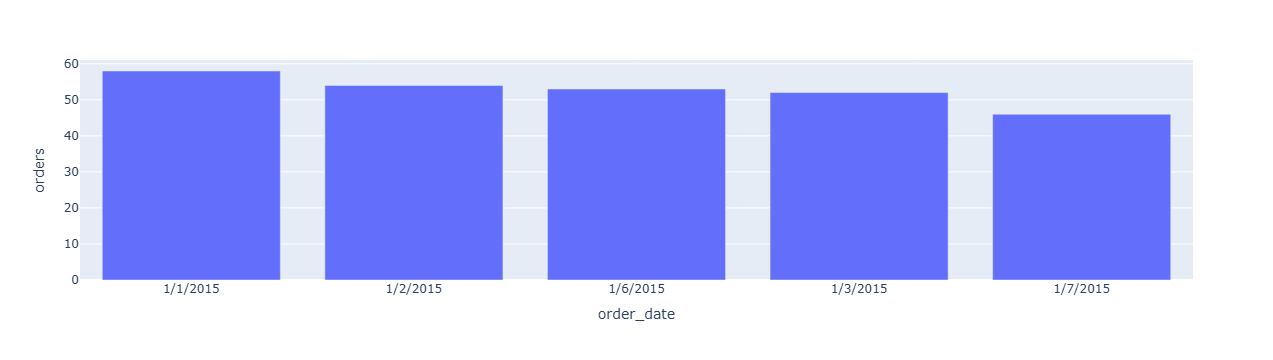

In [22]:
px.bar(top5_dates,x='order_date', y='orders')

In [23]:
pizza_df['total_qty']= pizza_df['total_qty'].astype(int)

In [24]:
pizza_size = pizza_df.groupby('min_pizza_size').agg({'total_qty':'sum'}).reset_index()

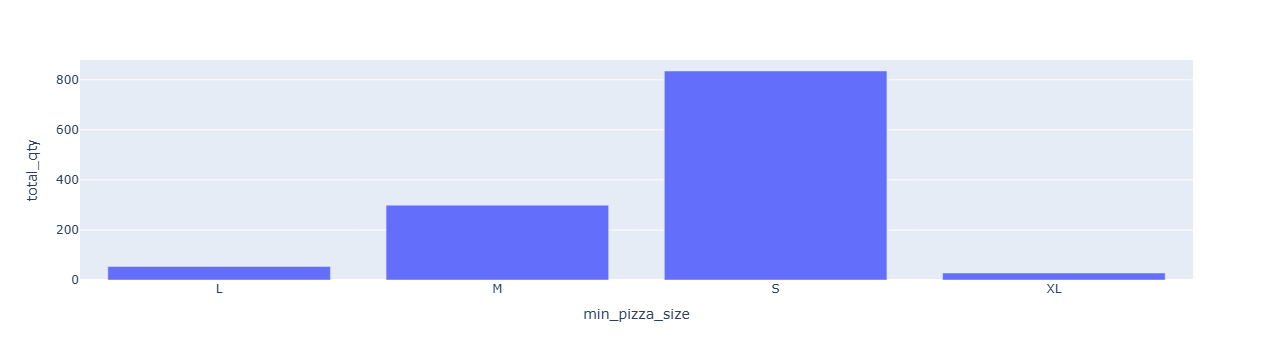

In [25]:
px.bar(pizza_size,x= 'min_pizza_size', y= 'total_qty')

In [26]:
pizza_df['full_date']= pizza_df['order_date']+' '+pizza_df['order_time']

In [27]:
pizza_df['full_date']=pd.to_datetime(pizza_df['full_date'],format='%m/%d/%Y %H:%M:%S')

In [28]:
hour_orders = pizza_df.groupby(pizza_df['full_date'].dt.hour).agg({'order_id':'nunique'}).reset_index()

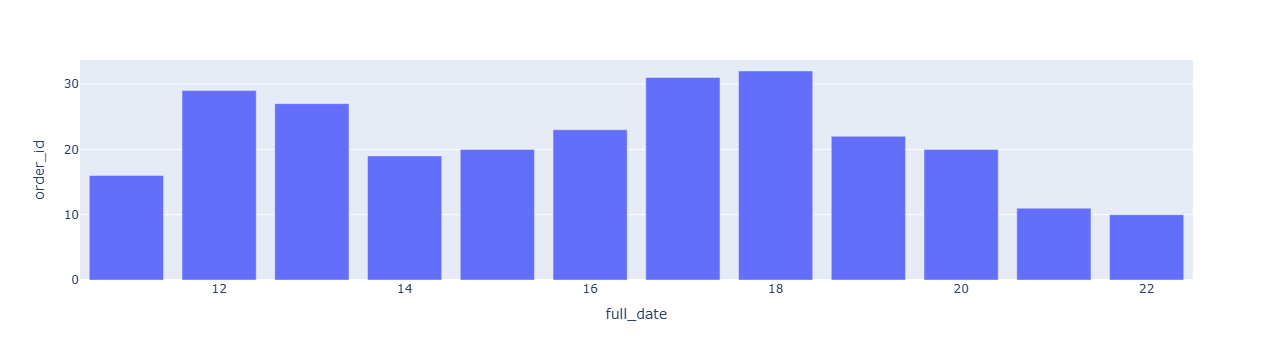

In [29]:
px.bar(hour_orders,x='full_date',y='order_id')

# Date-25.08.26

In [32]:
pizza_df['total_price']=pizza_df['total_price'].astype(float)
pizza_df['total_qty']=pizza_df['total_qty'].astype(float)
pizza_df['order_id']=pizza_df['order_id'].astype(float)

In [38]:
Pizza_table = pizza_df.groupby('pizza_category').agg({'total_price':'mean','total_qty':'mean','order_id':'nunique'})

In [42]:
Pizza_table

,total_price,total_qty,order_id
pizza_category,,,
Chicken,59.662857,3.514286,62
Classic,49.554054,3.054054,71
Supreme,64.200000,3.810811,97
Veggie,54.636842,3.378947,86


In [43]:
for column in Pizza_table.columns:
    if Pizza_table[col].dtypes!='str':
        Pizza_table[col]= Pizza_table[col].apply(lambda x : round(x))    

In [41]:
Pizza_table

,total_price,total_qty,order_id
pizza_category,,,
Chicken,59.662857,3.514286,62
Classic,49.554054,3.054054,71
Supreme,64.200000,3.810811,97
Veggie,54.636842,3.378947,86


In [44]:
pizza_df['full_date'].dt.day.unique()

array([1, 2, 3, 4, 5, 6, 7, 8], dtype=int32)

In [45]:
pizza_df['total_sale']= pizza_df['total_qty']*pizza_df['total_price']

In [46]:
day_sale= pizza_df.groupby(pizza_df['full_date'].dt.day).agg({'total_sale':'sum'}).reset_index()

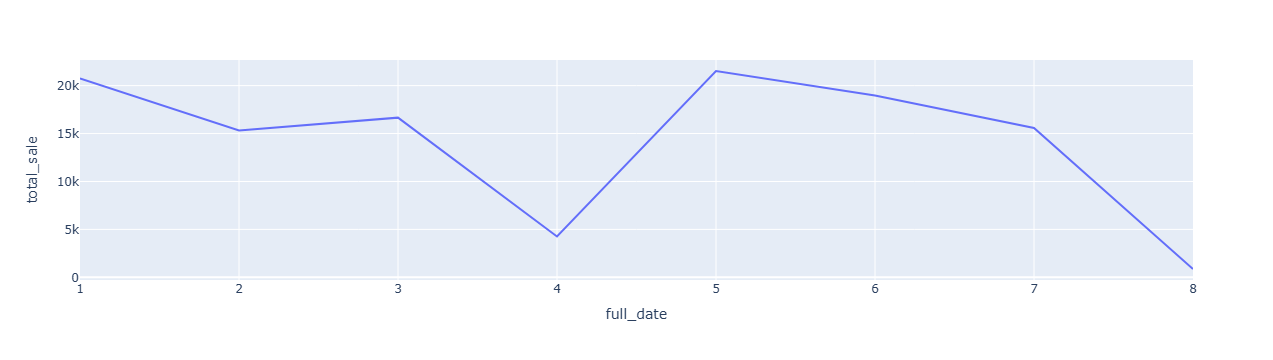

In [48]:
px.line(day_sale,x='full_date', y='total_sale')